In [5]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"

signal = np.loadtxt(
    NORMALIZED_DIR / "normal.csv",
    delimiter=","
)[0]

print("Original signal:", signal.shape)
print("Min:", signal.min())
print("Max:", signal.max())

Original signal: (100000,)
Min: 0.0
Max: 1.0


In [7]:
import numpy as np
from scipy.signal import resample


def resample_signal(signal, size):
    """
    Resample a 1D signal to `size` temporal points.
    """
    return resample(signal, size)


def normalize_to_minus_one_one(signal):
    """
    Convert a signal from [0, 1] to [-1, 1].
    """
    return 2.0 * signal - 1.0


def create_gasf(signal):
    """
    Generate Gramian Angular Summation Field.

    GASF(i,j) = cos(theta_i + theta_j)

    where theta = arccos(x).
    """

    x = np.clip(signal, -1.0, 1.0)

    theta = np.arccos(x)

    return np.cos(theta[:, None] + theta[None, :])


def create_gadf(signal):
    """
    Generate Gramian Angular Difference Field.

    GADF(i,j) = sin(theta_i - theta_j)
    """

    x = np.clip(signal, -1.0, 1.0)

    theta = np.arccos(x)

    return np.sin(theta[:, None] - theta[None, :])


def signal_to_gaf(signal, image_size=224):
    """
    Convert a normalized [0,1] signal to GASF and GADF.
    """

    reduced = resample_signal(signal, image_size)

    reduced = np.clip(reduced, 0.0, 1.0)

    reduced = normalize_to_minus_one_one(reduced)

    gasf = create_gasf(reduced)
    gadf = create_gadf(reduced)

    return gasf.astype(np.float32), gadf.astype(np.float32)

In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"

signal = np.loadtxt(
    NORMALIZED_DIR / "normal.csv",
    delimiter=","
)[0]

print("Original signal:", signal.shape)
print("Min:", signal.min())
print("Max:", signal.max())

Original signal: (100000,)
Min: 0.0
Max: 1.0


In [9]:
gasf, gadf = signal_to_gaf(
    signal,
    image_size=224
)

print("GASF:", gasf.shape)
print("GADF:", gadf.shape)

GASF: (224, 224)
GADF: (224, 224)


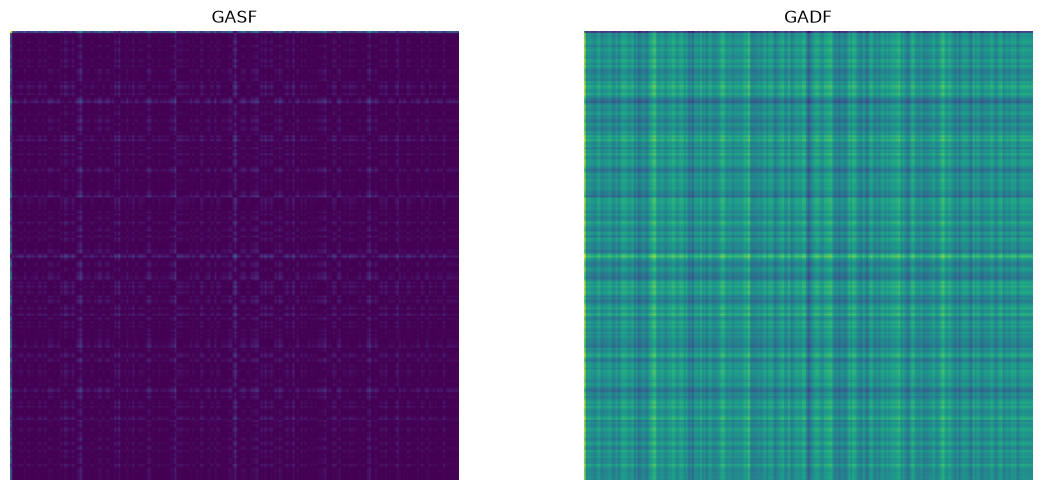

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gasf)
axes[0].set_title("GASF")
axes[0].axis("off")

axes[1].imshow(gadf)
axes[1].set_title("GADF")
axes[1].axis("off")

plt.tight_layout()
plt.show()

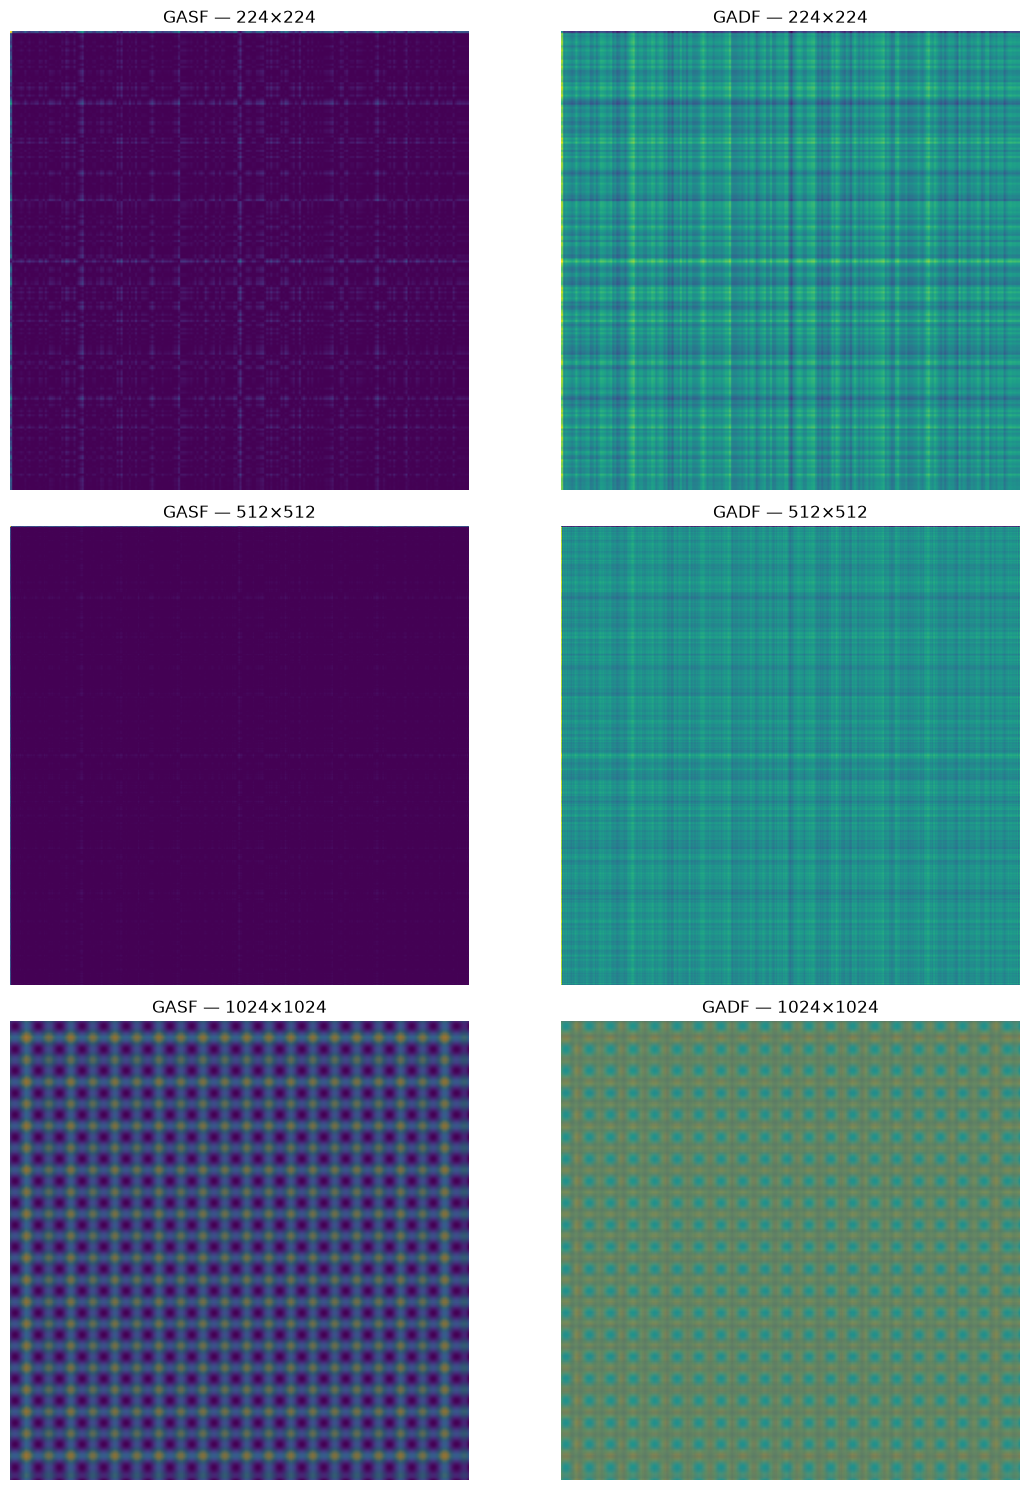

In [11]:
sizes = [224, 512, 1024]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 15)
)

for row, size in enumerate(sizes):

    gasf, gadf = signal_to_gaf(
        signal,
        image_size=size
    )

    axes[row, 0].imshow(gasf)
    axes[row, 0].set_title(f"GASF — {size}×{size}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(gadf)
    axes[row, 1].set_title(f"GADF — {size}×{size}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image

PROJECT_ROOT = Path.cwd().parent

NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"
IMAGE_DIR = PROJECT_ROOT / "datasets" / "images"

classes = ["normal", "irf", "orf"]
IMAGE_SIZE = 224

for representation in ["gasf", "gadf"]:
    for class_name in classes:
        (IMAGE_DIR / representation / class_name).mkdir(
            parents=True,
            exist_ok=True
        )


for class_name in classes:

    signals = np.loadtxt(
        NORMALIZED_DIR / f"{class_name}.csv",
        delimiter=","
    ).astype(np.float32)

    for i, signal in enumerate(signals):

        gasf, gadf = signal_to_gaf(
            signal,
            image_size=IMAGE_SIZE
        )

        representations = {
            "gasf": gasf,
            "gadf": gadf
        }

        for name, image in representations.items():

            # Convert [-1, 1] to [0, 255]
            image_uint8 = (
                (image + 1.0) / 2.0 * 255.0
            ).clip(0, 255).astype(np.uint8)

            output = (
                IMAGE_DIR
                / name
                / class_name
                / f"{class_name}_{i:03d}.png"
            )

            Image.fromarray(image_uint8).save(output)

    print(f"{class_name}: done")

normal: done
irf: done
orf: done


: 